In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import pandas as pd 

In [2]:
#Parameters 
N = 10     # no. of cells 
rho = 1   # Density (kg/m^3)
u = 0.1   # x component of velocity(m/s)
k = 0.1   # Diffusion Coefficient 
L = 1     # Domain length (m)
deltax = L/N  # cell size
D = k/deltax
F = rho*u


# Boundary Conditions
phi_wb = 1  #phi at west boundary
phi_eb = 0.1  #phi at east boundary


In [3]:
# Coordinates for different cells  
cell_coor = np.zeros(N+2,)
cell_coor[N+1] = L
cell_coor[1] = deltax/2
for n in np.arange(2,N+1):
    cell_coor[n] = cell_coor[n-1] + deltax


In [4]:
# Coefficient Matrix for TDMA Algorithm
# for boundary cells 
b1 = D-(F/2)
cN = D + F/2
d1 = (2*D + F)*phi_wb
dN = (2*D - F)*phi_eb
a1 = b1 + d1/phi_wb
aN = cN + dN/phi_eb

# for interior cells 
biN = D- F/2
ciN = D+ F/2
aiN = biN + ciN

coeff = np.zeros((N,4))  # each row denotes the coefficients of the discritized equation of a particular cell
for n in np.arange(0,N):
    if n==0:
        coeff[n,0] = a1
        coeff[n,1]= b1
        coeff[n,3]= d1
    elif n==N-1:
        coeff[n,0]= aN
        coeff[n,2]= cN
        coeff[n,3]= dN
    else:
        coeff[n,0]= aiN
        coeff[n,1]= biN
        coeff[n,2]= ciN

P = np.zeros(N,)
Q = np.zeros(N,)

P[0] = coeff[0,1]/coeff[0,0]
Q[0] = coeff[0,3]/coeff[0,0]
for n in np.arange(1,N):
    P[n] = coeff[n,1]/(coeff[n,0]-coeff[n,2]*P[n-1])
    Q[n] = (coeff[n,3]+coeff[n,2]*Q[n-1])/(coeff[n,0]-coeff[n,2]*P[n-1])


phi = np.zeros(N+2,)
phi[0] = phi_wb
phi[N+1] = phi_eb
# phi[N] = Q[N-1]
for n in np.arange(N,0,-1):
    if n==N:
        phi[N] = Q[N-1]
    else :
        phi[n] = phi[n+1]*P[n-1] + Q[n-1]
print(phi)



[1.         0.97384559 0.91603059 0.8521298  0.78150261 0.70344098
 0.61716233 0.52180172 0.41640315 0.29991    0.17115441 0.1       ]


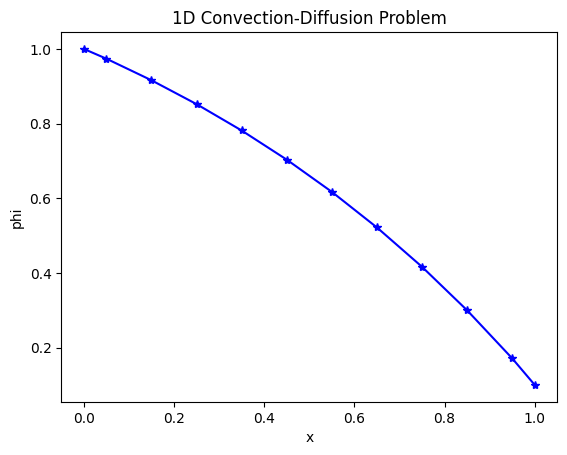

In [7]:
# Post processing 

plt.plot(cell_coor,phi,'b*-')
plt.xlabel('x')
plt.ylabel('phi')
# plt.xticks(cell_coor)
plt.title('1D Convection-Diffusion Problem')
plt.show()